<a href="https://colab.research.google.com/github/Alejandra300905/NLP_Polarity_of_film_reviews_and_the_problem_of_negation/blob/main/ProyectoClasificacionR_AlejandraB_CarlosM_NathalieL.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# R3.1 Polaridad de reseñas de cine y el problema de la negación

### Bitácora de Contribuciones del Equipo

| Etapa | Programó (Implementación) | Revisó (Código y Resultados) | Hizo la Presentación |
| :---: | :--- | :--- | :--- |
| **Etapa 1** | Carlos | Alejandra | Nathalie |
| **Etapa 2** | Alejandra | Nathalie | Carlos |
| **Etapa 3** | Nathalie | Carlos | Alejandra |


### Etapa 1 - **Análisis, representacion y baseline.** Limpieza (etiquetas HTML, puntuación) y división Train, Dev y Test. Baseline: bolsa de palabras de unigramas + Bayes ingenuo

In [1]:
import os
import tarfile
import pandas as pd
from google.colab import files

tar_filename = 'aclImdb_v1.tar.gz'

# Si no existe la carpeta extraída, procedemos a obtener el archivo
if not os.path.exists('aclImdb'):
    if not os.path.exists(tar_filename):
        print("Por favor, sube tu archivo aclImdb_v1.tar.gz:")
        uploaded = files.upload()
        # Renombrar en caso de que se haya subido con otro nombre similar
        for name in uploaded.keys():
            if 'tar.gz' in name or 'gtarz' in name:
                os.rename(name, tar_filename)
                break

    print("Extrayendo aclImdb_v1.tar.gz...")
    with tarfile.open(tar_filename, 'r:gz') as tar:
        tar.extractall()

def load_imdb_dataset(base_dir):
    data = []
    for split in ['train', 'test']:
        for sentiment in ['pos', 'neg']:
            folder = os.path.join(base_dir, split, sentiment)
            label = 1 if sentiment == 'pos' else 0
            if os.path.exists(folder):
                for filename in os.listdir(folder):
                    if filename.endswith('.txt'):
                        with open(os.path.join(folder, filename), 'r', encoding='utf-8') as f:
                            review = f.read()
                            data.append({'review': review, 'sentiment': label, 'split': split})
    return pd.DataFrame(data)

# Cargar los datos en un DataFrame
df = load_imdb_dataset('aclImdb')

# Mostrar información general del DataFrame
print(f"Dimensiones del DataFrame: {df.shape}")
display(df.head())

Por favor, sube tu archivo aclImdb_v1.tar.gz:


Saving aclImdb_v1.tar.gz to aclImdb_v1.tar.gz
Extrayendo aclImdb_v1.tar.gz...


/tmp/ipykernel_2069/1179249102.py:21: DeprecationWarning: Python 3.14 will, by default, filter extracted tar archives and reject files or modify their metadata. Use the filter argument to control this behavior.
  tar.extractall()


Dimensiones del DataFrame: (50000, 3)


,review,sentiment,split
0,"With all the ""Adult"" innuendos in todays famil...",1,train
1,The Dentist starts on the morning of Dr. Alan ...,1,train
2,"If you enjoy the subtle (yes, I said subtle) a...",1,train
3,This film was amazing. It is an inspiring piec...,1,train
4,"I just saw this last night, it was broadcast o...",1,train


In [2]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 3 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   review     50000 non-null  object
 1   sentiment  50000 non-null  int64 
 2   split      50000 non-null  object
dtypes: int64(1), object(2)
memory usage: 1.1+ MB


In [3]:
df.split.values

array(['train', 'train', 'train', ..., 'test', 'test', 'test'],
      dtype=object)

In [4]:
# Mostrar los valores únicos y la cantidad de registros para cada split
display(df['split'].value_counts())

,count
split,
train,25000
test,25000


In [5]:
# Mostrar algunas reseñas de ejemplo completas
print("Ejemplo de Reseña Positiva:")
print(df[df['sentiment'] ==1 ]['review'].iloc[0])
print("\n" + "="*80 + "\n")
print("Ejemplo de Reseña Negativa:")
print(df[df['sentiment'] == 0]['review'].iloc[0])


Ejemplo de Reseña Positiva:
With all the "Adult" innuendos in todays family movies its nice to see one where you don't have to worry about that and can just sit back and enjoy a family with your kids. Yes, this movie might have a few swear-words (there's that time where Knox swears, but they don't let you hear the full words), but for the most part this movie is truly as clean as they come (and that's including movies from back in the day). Not only that, its very enjoyable, one of my favorites, and just a great clean and fun movie to watch with the family.<br /><br />The only thing I have against this movie is that it is too short and I wish there could be more of some of the memorable parts that are in it, I'm not going to mention them because I don't want any spoilers here.<br /><br />All in all nicely done and a great movie to watch; so go out and get the kids, make some cookies, and watch this movie!


Ejemplo de Reseña Negativa:
If this movie should be renamed, it should be "The 

## Positiva
- En: This is a gem of a movie not just for people who like fun and quirky premises, but who love the history and traditions of Sci-Fi and Classic Hollywood movies. Each alien of the Martian crew is the embodiment of a classic Sci-Fi character or member of Hollywood royalty and it's pure pleasure watching them bounce of each other and the residents of Big Bean.
---
- Es: Esta película es una auténtica joya, no solo para quienes disfrutan de premisas divertidas y peculiares, sino también para los amantes de la historia y las tradiciones de la ciencia ficción y el cine clásico de Hollywood. Cada alienígena de la tripulación marciana encarna a un personaje clásico de la ciencia ficción o a una figura emblemática de Hollywood; es un verdadero placer ver cómo interactúan entre ellos y con los habitantes de Big Bean.

## Negativa
- En: 'Anita and Me' is a drama about growing up in multi-ethnic Britain, rather like 'Bend it Like Beckham', or more closely, 'East is East', with which it shares a 1970s setting. The tone is resolutely chirpy (in spite of the dour Black Country accents), but the film lacks 'East is East's vigour and the result seems rather thin and trite. Moreover, the portrayal of the film's central relationship, between an Asian girl and her white friend, is insufficiently deep to justify the way that the movie is structured around it. I have also grown tired of films where the hero years to be a writer, this is naturally often something that real writers have experienced, but hardly a fresh element in a fictional story. 'East is East' was fun and sharp; 'Anita and Me' seems obvious and dull in comparison.

---
- Es: «Anita and Me» es un drama sobre el proceso de madurar en una Gran Bretaña multiétnica; recuerda a «Bend It Like Beckham» o, más aún, a «East Is East», con la que comparte una ambientación en la década de 1970. El tono es decididamente alegre (a pesar de los ásperos acentos de la región de Black Country), pero a la película le falta el vigor de «East Is East», por lo que el resultado parece bastante superficial y trillado. Además, el retrato de la relación central —entre una chica de origen asiático y su amiga blanca— carece de la profundidad necesaria para justificar que la película se estructure en torno a ella. Por otra parte, ya me han cansado las películas en las que el protagonista anhela convertirse en escritor; si bien es algo que muchos escritores han vivido en la realidad, no deja de ser un recurso poco original en una obra de ficción. «East Is East» era divertida e ingeniosa; en comparación, «Anita and Me» resulta predecible y aburrida.

count    50000.000000
mean       231.156940
std        171.343997
min          4.000000
25%        126.000000
50%        173.000000
75%        280.000000
max       2470.000000
Name: n_palabras, dtype: float64


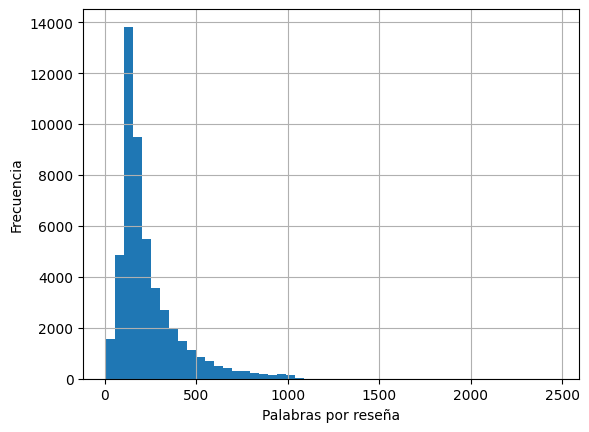

Con <br />: 29200


In [6]:
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score, classification_report

# Balance de clases y tamaño de cada partición
#print(df.groupby(["split", "sentiment"]).size().unstack())

# Longitud de reseñas (en palabras)
df["n_palabras"] = df["review"].str.split().str.len()
print(df["n_palabras"].describe())

df["n_palabras"].hist(bins=50)
plt.xlabel("Palabras por reseña"); plt.ylabel("Frecuencia")
plt.show()

# ¿Cuántas reseñas tienen etiquetas HTML?
print("Con <br />:", df["review"].str.contains("<br", regex=False).sum())

In [7]:
# Encontrar los índices de las reseñas con menos y más palabras
idx_min = df['n_palabras'].idxmin()
idx_max = df['n_palabras'].idxmax()

print(f"=== RESEÑA CON MENOS PALABRAS ({df.loc[idx_min, 'n_palabras']} palabras) ===")
print(f"Sentiment: {'Positivo' if df.loc[idx_min, 'sentiment'] == 1 else 'Negativo'}")
print(df.loc[idx_min, 'review'])
print("\n" + "="*50 + "\n")

print(f"=== RESEÑA CON MÁS PALABRAS ({df.loc[idx_max, 'n_palabras']} palabras) ===")
print(f"Sentiment: {'Positivo' if df.loc[idx_max, 'sentiment'] == 1 else 'Negativo'}")
# Mostramos los primeros 1500 caracteres para no saturar la pantalla, pero se puede imprimir completa
print(df.loc[idx_max, 'review'][:1500] + '\n... [TRUNCADO]')


=== RESEÑA CON MENOS PALABRAS (4 palabras) ===
Sentiment: Negativo
Primary plot!Primary direction!Poor interpretation.


=== RESEÑA CON MÁS PALABRAS (2470 palabras) ===
Sentiment: Positivo
Match 1: Tag Team Table Match Bubba Ray and Spike Dudley vs Eddie Guerrero and Chris Benoit Bubba Ray and Spike Dudley started things off with a Tag Team Table Match against Eddie Guerrero and Chris Benoit. According to the rules of the match, both opponents have to go through tables in order to get the win. Benoit and Guerrero heated up early on by taking turns hammering first Spike and then Bubba Ray. A German suplex by Benoit to Bubba took the wind out of the Dudley brother. Spike tried to help his brother, but the referee restrained him while Benoit and Guerrero ganged up on him in the corner. With Benoit stomping away on Bubba, Guerrero set up a table outside. Spike dashed into the ring and somersaulted over the top rope onto Guerrero on the outside! After recovering and taking care of Spike, Gu

In [8]:
def limpiar(texto):
    texto = re.sub(r"<[^>]+>", " ", texto)      # quita etiquetas HTML
    texto = texto.lower()                        # minúsculas
    texto = re.sub(r"[^a-z' ]", " ", texto)      # quita puntuación, números y símbolos (conserva ')
    texto = re.sub(r"\s+", " ", texto).strip()   # colapsa espacios
    return texto

df["clean"] = df["review"].apply(limpiar)
print(df.loc[0, "review"][:200])
print(df.loc[0, "clean"][:200])

With all the "Adult" innuendos in todays family movies its nice to see one where you don't have to worry about that and can just sit back and enjoy a family with your kids. Yes, this movie might have 
with all the adult innuendos in todays family movies its nice to see one where you don't have to worry about that and can just sit back and enjoy a family with your kids yes this movie might have a fe


In [9]:
df.head()

,review,sentiment,split,n_palabras,clean
0,"With all the ""Adult"" innuendos in todays famil...",1,train,174,with all the adult innuendos in todays family ...
1,The Dentist starts on the morning of Dr. Alan ...,1,train,679,the dentist starts on the morning of dr alan f...
2,"If you enjoy the subtle (yes, I said subtle) a...",1,train,164,if you enjoy the subtle yes i said subtle acti...
3,This film was amazing. It is an inspiring piec...,1,train,136,this film was amazing it is an inspiring piece...
4,"I just saw this last night, it was broadcast o...",1,train,225,i just saw this last night it was broadcast on...


In [10]:
train_full = df[df["split"] == "train"]
test = df[df["split"] == "test"]      # se queda intacto hasta el final

train, dev = train_test_split(
    train_full,
    test_size=0.2,
    stratify=train_full["sentiment"],
    random_state=42
)

print(len(train), len(dev), len(test))   # 20000, 5000, 25000

20000 5000 25000


In [11]:
vectorizer = CountVectorizer(
    ngram_range=(1,1),
    token_pattern=r"[a-z]+(?:'[a-z]+)*",   # conserva didn't, isn't...
    min_df=2
)
X_train = vectorizer.fit_transform(train["clean"])   # fit SOLO con train
X_dev   = vectorizer.transform(dev["clean"])
X_test  = vectorizer.transform(test["clean"])

y_train, y_dev, y_test = train["sentiment"], dev["sentiment"], test["sentiment"]
print("Vocabulario:", len(vectorizer.vocabulary_))

nb = MultinomialNB(alpha=1.0)
nb.fit(X_train, y_train)

Vocabulario: 42709


MultinomialNB()

In [12]:
print(X_train[:3])

<Compressed Sparse Row sparse matrix of dtype 'int64'
	with 424 stored elements and shape (3, 42709)>
  Coords	Values
  (0, 18285)	12
  (0, 16547)	4
  (0, 24457)	1
  (0, 13563)	1
  (0, 14349)	4
  (0, 21734)	1
  (0, 40415)	1
  (0, 42250)	2
  (0, 1255)	14
  (0, 10272)	1
  (0, 5112)	2
  (0, 3386)	1
  (0, 3807)	2
  (0, 41594)	2
  (0, 35988)	2
  (0, 41317)	2
  (0, 19761)	13
  (0, 5066)	3
  (0, 12166)	1
  (0, 40192)	1
  (0, 21941)	1
  (0, 42162)	3
  (0, 25997)	4
  (0, 5237)	2
  (0, 41032)	3
  :	:
  (2, 13035)	1
  (2, 10338)	1
  (2, 41575)	2
  (2, 14880)	1
  (2, 10126)	1
  (2, 252)	1
  (2, 23994)	1
  (2, 28177)	1
  (2, 17226)	1
  (2, 38121)	1
  (2, 42472)	2
  (2, 13846)	1
  (2, 26813)	1
  (2, 33421)	2
  (2, 2873)	1
  (2, 13311)	1
  (2, 11513)	1
  (2, 4526)	1
  (2, 9199)	1
  (2, 37409)	1
  (2, 20735)	1
  (2, 42474)	1
  (2, 17009)	1
  (2, 22369)	1
  (2, 21445)	1


In [13]:
# Tomamos el texto limpio de la primera fila del conjunto de train como ejemplo
ejemplo_texto = train["clean"].iloc[2]
ejemplo_vectorizado = X_train[2]

print("Texto original limpio:")
print(ejemplo_texto)
print("\n" + "="*50 + "\n")

print("Representación en la Matriz Dispersa (Sparse Matrix) - (Fila, ID_Vocabulario) Frecuencia:")
print(ejemplo_vectorizado)
print("\n" + "="*50 + "\n")

# Mapeamos los IDs de vuelta a las palabras correspondientes del vocabulario
print("Palabras presentes en este texto y sus frecuencias:")
nombres_caracteristicas = vectorizer.get_feature_names_out()
coordenadas = ejemplo_vectorizado.tocoo()
for col, val in zip(coordenadas.col, coordenadas.data):
    print(f"- '{nombres_caracteristicas[col]}' (ID: {col}): {val} vez/veces")


Texto original limpio:
i first saw jake gyllenhaal in jarhead a little while back and since then i've been watching every one of his movies that arrives on my radar screen like clive owen he has an intensity and he even resembles owen somewhat that just oozes from the screen i feel sure that if he lands some meaty roles he'll crack an oscar one day that's not to denigrate this film at all it's a fine story with very believable people well it's based upon the author's early shenanigans with rocketry a great cast chris cooper is always good and laura dern is always on my watch list with the appropriate mix of humor pathos excitement and the great sound track with so many rock n roll oldies to get the feet tapping but this film had a very special significance for me in i was the same age as homer hickham like him i looked up at the night stars to watch sputnik as it scudded across the blackness like homer also i experimented with rocketry in my backyard and used even the exact same chemic

In [14]:
def evaluar(modelo, X, y, nombre):
    pred = modelo.predict(X)
    proba = modelo.predict_proba(X)[:, 1]
    print(f"── {nombre} ──")
    print(f"Exactitud: {accuracy_score(y, pred):.4f}")
    print(f"F1:        {f1_score(y, pred):.4f}")
    print(f"AUC-ROC:   {roc_auc_score(y, proba):.4f}")
    return pred

pred_dev = evaluar(nb, X_dev, y_dev, "Dev")
print(classification_report(y_dev, pred_dev, target_names=["neg", "pos"]))

# Test: úsalo UNA sola vez, cuando el baseline esté definitivo
pred_test = evaluar(nb, X_test, y_test, "Test")

── Dev ──
Exactitud: 0.8410
F1:        0.8334
AUC-ROC:   0.9180
              precision    recall  f1-score   support

         neg       0.81      0.89      0.85      2500
         pos       0.88      0.80      0.83      2500

    accuracy                           0.84      5000
   macro avg       0.84      0.84      0.84      5000
weighted avg       0.84      0.84      0.84      5000

── Test ──
Exactitud: 0.8130
F1:        0.8002
AUC-ROC:   0.8906


In [15]:
# Seleccionamos una reseña del conjunto de desarrollo (por ejemplo, la primera)
indice_ejemplo = 0
texto_original = dev["review"].iloc[indice_ejemplo]
texto_limpio = dev["clean"].iloc[indice_ejemplo]
etiqueta_real = dev["sentiment"].iloc[indice_ejemplo]

# Transformamos el texto con el vectorizer para que tenga el formato adecuado
vector_ejemplo = X_dev[indice_ejemplo]

# Obtenemos las probabilidades de cada clase
probabilidades = nb.predict_proba(vector_ejemplo)[0]
prediccion = nb.predict(vector_ejemplo)[0]

print("=== TEXTO DE LA RESEÑA ===")
print(texto_original[:500] + ("..." if len(texto_original) > 500 else ""))
print("\n" + "="*30)
print(f"Etiqueta Real: {'Positivo (1)' if etiqueta_real == 1 else 'Negativo (0)'}")
print(f"Predicción del Modelo: {'Positivo (1)' if prediccion == 1 else 'Negativo (0)'}")
print("="*30)
print(f"Probabilidad de ser NEGATIVA (0): {probabilidades[0]:.6f} ({probabilidades[0]*100:.4f}%)")
print(f"Probabilidad de ser POSITIVA (1): {probabilidades[1]:.6f} ({probabilidades[1]*100:.4f}%)")


=== TEXTO DE LA RESEÑA ===
My husband and I enjoy The DoodleBops as much as our 8 month old baby does. We have bought him DVD's and CD's just so we can watch and listen to them ourselves. They are fun, energetic, and very entertaining. They encourage children to be active, share and care. They always have a positive message along with fun entertainment. Every time our son hears the theme song he quickly turns his head toward the television and starts bouncing up and down in excitement. Dee Dee is a wonderful singer, she h...

Etiqueta Real: Positivo (1)
Predicción del Modelo: Positivo (1)
Probabilidad de ser NEGATIVA (0): 0.000000 (0.0000%)
Probabilidad de ser POSITIVA (1): 1.000000 (100.0000%)


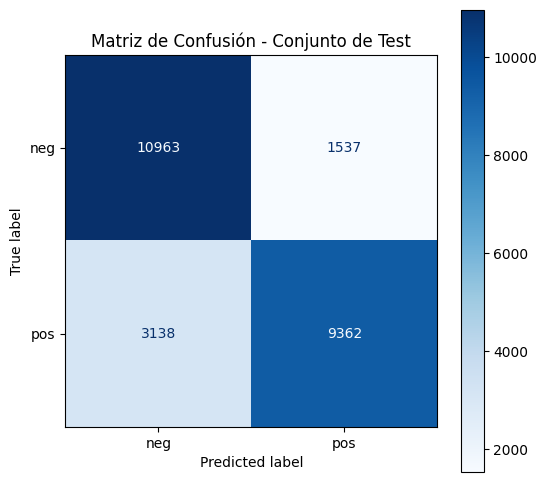

Verdaderos Negativos (TN): 10963
Falsos Positivos (FP): 1537
Falsos Negativos (FN): 3138
Verdaderos Positivos (TP): 9362


In [16]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Calcular la matriz de confusión usando las etiquetas reales de test (y_test) y las predicciones (pred_test)
cm = confusion_matrix(y_test, pred_test)

# Crear la visualización de la matriz de confusión
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["neg", "pos"])

# Graficar la matriz
fig, ax = plt.subplots(figsize=(6, 6))
disp.plot(ax=ax, cmap=plt.cm.Blues, values_format='d')
plt.title("Matriz de Confusión - Conjunto de Test")
plt.show()

# Imprimir también los valores numéricos directos
tn, fp, fn, tp = cm.ravel()
print(f"Verdaderos Negativos (TN): {tn}")
print(f"Falsos Positivos (FP): {fp}")
print(f"Falsos Negativos (FN): {fn}")
print(f"Verdaderos Positivos (TP): {tp}")


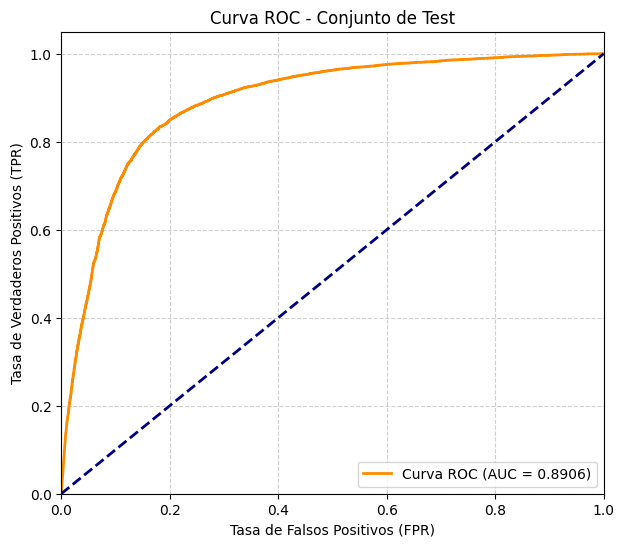

In [17]:
from sklearn.metrics import roc_curve, auc

proba_test = nb.predict_proba(X_test)[:, 1]

fpr, tpr, _ = roc_curve(y_test, proba_test)
roc_auc = auc(fpr, tpr)

plt.figure(figsize=(7, 6))
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'Curva ROC (AUC = {roc_auc:.4f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('Tasa de Falsos Positivos (FPR)')
plt.ylabel('Tasa de Verdaderos Positivos (TPR)')
plt.title('Curva ROC - Conjunto de Test')
plt.legend(loc="lower right")
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()


### Etapa 2 - **Primera aproximación**. TF-IDF de unigramas y bigramas + regresión logística, con y sin marcado de negación

2.1 Modelo A: TF-IDF (unigramas + bigramas) + Regresión Logística, **sin** marcado de negación

In [18]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression

# TF-IDF con unigramas y bigramas sobre el texto limpio de la Etapa 1
tfidf_A = TfidfVectorizer(
    ngram_range=(1, 2),
    token_pattern=r"[a-z]+(?:'[a-z]+)*",   # conserva didn't, isn't...
    min_df=2,
    sublinear_tf=True
)
XA_train = tfidf_A.fit_transform(train["clean"])   # fit SOLO con train
XA_dev   = tfidf_A.transform(dev["clean"])
XA_test  = tfidf_A.transform(test["clean"])
print("Vocabulario (uni+bigramas):", len(tfidf_A.vocabulary_))

# Elegimos C (regularización) con el conjunto Dev
mejor_C_A, mejor_auc_A = None, -1
for C in [0.1, 0.5, 1, 5, 10, 50, 70, 90]:
    m = LogisticRegression(C=C, max_iter=2000, solver="liblinear")
    m.fit(XA_train, y_train)
    auc_dev = roc_auc_score(y_dev, m.predict_proba(XA_dev)[:, 1])
    print(f"C={C:<5} AUC Dev = {auc_dev:.4f}")
    if auc_dev > mejor_auc_A:
        mejor_C_A, mejor_auc_A = C, auc_dev
print("Mejor C:", mejor_C_A)

lr_A = LogisticRegression(C=mejor_C_A, max_iter=2000, solver="liblinear")
lr_A.fit(XA_train, y_train)
pred_dev_A = evaluar(lr_A, XA_dev, y_dev, "Modelo A - Dev (sin negación)")
print(classification_report(y_dev, pred_dev_A, target_names=["neg", "pos"]))

Vocabulario (uni+bigramas): 362738
C=0.1   AUC Dev = 0.9400
C=0.5   AUC Dev = 0.9577
C=1     AUC Dev = 0.9627
C=5     AUC Dev = 0.9685
C=10    AUC Dev = 0.9694
C=50    AUC Dev = 0.9700
C=70    AUC Dev = 0.9701
C=90    AUC Dev = 0.9701
Mejor C: 90
── Modelo A - Dev (sin negación) ──
Exactitud: 0.9092
F1:        0.9096
AUC-ROC:   0.9701
              precision    recall  f1-score   support

         neg       0.91      0.90      0.91      2500
         pos       0.91      0.91      0.91      2500

    accuracy                           0.91      5000
   macro avg       0.91      0.91      0.91      5000
weighted avg       0.91      0.91      0.91      5000



### Interpretación del Modelo A

En esta etapa se utilizó TF-IDF con unigramas y bigramas para representar numéricamente las reseñas. Posteriormente, entrenamos una regresión logística para clasificarlas como positivas o negativas.

El uso de bigramas permite considerar pares de palabras consecutivas y capturar expresiones como "not good".

2.2 Marcado de negación

In [19]:
NEGACIONES = {"not", "no", "never", "none", "nobody", "nothing", "nowhere",
              "neither", "nor", "cannot", "without", "hardly", "barely", "scarcely"}
TOKEN_RE = re.compile(r"[a-z]+(?:'[a-z]+)*|[.,;:!?()]")   # palabras o signos de puntuación
PUNTUACION = set(".,;:!?()")

def es_negacion(tok):
    return tok in NEGACIONES or tok.endswith("n't")      # didn't, isn't, don't, can't...

def marcar_negacion(texto):
    texto = re.sub(r"<[^>]+>", " ", texto).lower()
    salida, en_negacion = [], False
    for tok in TOKEN_RE.findall(texto):
        if tok in PUNTUACION:                            # la puntuación cierra el alcance
            en_negacion = False
            continue                                     # y se descarta
        salida.append("NEG_" + tok if en_negacion else tok)
        if es_negacion(tok):                             # a partir de aquí, se marca
            en_negacion = True
    return " ".join(salida)

# Ejemplos para verificar la regla
ejemplos = [
    "This movie is not good, it was a waste.",
    "I didn't like the acting or the plot. Great music!",
    "Not bad at all<br />but never boring; fun",
]
for e in ejemplos:
    print("ORIGINAL:", e)
    print("MARCADO :", marcar_negacion(e), "\n")

df["clean_neg"] = df["review"].apply(marcar_negacion)
train = df.loc[train.index]; dev = df.loc[dev.index]; test = df.loc[test.index]   # mismas particiones, con la nueva columna
print(dev["clean_neg"].iloc[0][:300])

ORIGINAL: This movie is not good, it was a waste.
MARCADO : this movie is not NEG_good it was a waste 

ORIGINAL: I didn't like the acting or the plot. Great music!
MARCADO : i didn't NEG_like NEG_the NEG_acting NEG_or NEG_the NEG_plot great music 

ORIGINAL: Not bad at all<br />but never boring; fun
MARCADO : not NEG_bad NEG_at NEG_all NEG_but NEG_never NEG_boring fun 

my husband and i enjoy the doodlebops as much as our month old baby does we have bought him dvd's and cd's just so we can watch and listen to them ourselves they are fun energetic and very entertaining they encourage children to be active share and care they always have a positive message along with


### Marcado explícito de negación

La función identifica palabras de negación y marca los tokens siguientes con el prefijo `NEG_` hasta encontrar un signo de puntuación reconocido.

Esta transformación busca distinguir palabras como `good` y `NEG_good`.

2.3 Modelo B: TF-IDF (unigramas + bigramas) + Regresión Logística, **con** marcado de negación

In [20]:
tfidf_B = TfidfVectorizer(
    ngram_range=(1, 2),
    token_pattern=r"[A-Za-z_]+(?:'[a-z]+)*",   # acepta NEG_palabra
    lowercase=False,                            # ya está en minúsculas; así no se altera NEG_
    min_df=2,
    sublinear_tf=True
)
XB_train = tfidf_B.fit_transform(train["clean_neg"])   # fit SOLO con train
XB_dev   = tfidf_B.transform(dev["clean_neg"])
XB_test  = tfidf_B.transform(test["clean_neg"])
print("Vocabulario (uni+bigramas, con NEG_):", len(tfidf_B.vocabulary_))
mejor_C_B, mejor_auc_B = None, -1
for C in [0.1, 0.5, 1, 5, 10, 50, 70, 90]:
    m = LogisticRegression(C=C, max_iter=2000, solver="liblinear")
    m.fit(XB_train, y_train)
    auc_dev = roc_auc_score(y_dev, m.predict_proba(XB_dev)[:, 1])
    print(f"C={C:<5} AUC Dev = {auc_dev:.4f}")
    if auc_dev > mejor_auc_B:
        mejor_C_B, mejor_auc_B = C, auc_dev
print("Mejor C:", mejor_C_B)

lr_B = LogisticRegression(C=mejor_C_B, max_iter=2000, solver="liblinear")
lr_B.fit(XB_train, y_train)
pred_dev_B = evaluar(lr_B, XB_dev, y_dev, "Modelo B - Dev (con negación)")
print(classification_report(y_dev, pred_dev_B, target_names=["neg", "pos"]))

Vocabulario (uni+bigramas, con NEG_): 390884
C=0.1   AUC Dev = 0.9354
C=0.5   AUC Dev = 0.9565
C=1     AUC Dev = 0.9621
C=5     AUC Dev = 0.9684
C=10    AUC Dev = 0.9693
C=50    AUC Dev = 0.9700
C=70    AUC Dev = 0.9700
C=90    AUC Dev = 0.9700
Mejor C: 90
── Modelo B - Dev (con negación) ──
Exactitud: 0.9110
F1:        0.9114
AUC-ROC:   0.9700
              precision    recall  f1-score   support

         neg       0.91      0.91      0.91      2500
         pos       0.91      0.92      0.91      2500

    accuracy                           0.91      5000
   macro avg       0.91      0.91      0.91      5000
weighted avg       0.91      0.91      0.91      5000



In [21]:
print(XB_train[:3])

<Compressed Sparse Row sparse matrix of dtype 'float64'
	with 984 stored elements and shape (3, 390884)>
  Coords	Values
  (0, 195827)	0.03164509373261445
  (0, 179661)	0.03499416073316786
  (0, 238893)	0.040784198716670224
  (0, 158317)	0.03992115754029461
  (0, 164781)	0.017345821653152585
  (0, 222220)	0.05137752370594291
  (0, 366138)	0.06810140900993386
  (0, 387291)	0.04896770421858285
  (0, 74218)	0.025924369691217333
  (0, 137516)	0.030573639702899738
  (0, 108900)	0.022543068572762403
  (0, 99157)	0.06973646682580371
  (0, 101953)	0.1080134306993281
  (0, 376921)	0.02585688331698044
  (0, 319579)	0.05586919917788881
  (0, 373197)	0.021960089889101364
  (0, 208725)	0.02881913629906332
  (0, 107781)	0.016979069396733066
  (0, 147926)	0.036215816568629045
  (0, 364391)	0.01578639759139878
  (0, 224569)	0.049653287738734966
  (0, 386312)	0.03398968939003979
  (0, 251751)	0.026716418577913174
  (0, 9089)	0.045320134844213704
  (0, 25355)	0.034914520833418436
  :	:
  (2, 243549)	0.0

### Entrenamiento del Modelo B

Se aplica TF-IDF al texto con negaciones marcadas y se entrena una regresión logística. Se mantiene el mismo procedimiento de selección de C utilizado en el Modelo A para facilitar la comparación.

2.4 Comparación: Baseline vs Modelo A vs Modelo B

In [22]:
def metricas(modelo, X, y):
    pred = modelo.predict(X)
    proba = modelo.predict_proba(X)[:, 1]
    return {"Exactitud": accuracy_score(y, pred),
            "F1": f1_score(y, pred),
            "AUC-ROC": roc_auc_score(y, proba)}

resultados = {
    "Baseline: BoW + Naive Bayes":         (metricas(nb,   X_dev,  y_dev), metricas(nb,   X_test,  y_test)),
    "A: TF-IDF 1-2g + LR (sin negación)":  (metricas(lr_A, XA_dev, y_dev), metricas(lr_A, XA_test, y_test)),
    "B: TF-IDF 1-2g + LR (con negación)":  (metricas(lr_B, XB_dev, y_dev), metricas(lr_B, XB_test, y_test)),
}

filas = []
for nombre, (m_dev, m_test) in resultados.items():
    fila = {"Modelo": nombre}
    fila.update({f"Dev {k}": v for k, v in m_dev.items()})
    fila.update({f"Test {k}": v for k, v in m_test.items()})
    filas.append(fila)

tabla = pd.DataFrame(filas).set_index("Modelo").round(4)
display(tabla)

# Efecto del marcado de negación (B - A) en Test
print("\nMejora por marcado de negación (B - A) en Test:")
for k in ["Exactitud", "F1", "AUC-ROC"]:
    d = resultados["B: TF-IDF 1-2g + LR (con negación)"][1][k] - resultados["A: TF-IDF 1-2g + LR (sin negación)"][1][k]
    print(f"  {k:<10}: {d:+.4f}")

,Dev Exactitud,Dev F1,Dev AUC-ROC,Test Exactitud,Test F1,Test AUC-ROC
Modelo,,,,,,
Baseline: BoW + Naive Bayes,0.8410,0.8334,0.9180,0.8130,0.8002,0.8906
A: TF-IDF 1-2g + LR (sin negación),0.9092,0.9096,0.9701,0.9048,0.9048,0.9654
B: TF-IDF 1-2g + LR (con negación),0.9110,0.9114,0.9700,0.9049,0.9050,0.9661



Mejora por marcado de negación (B - A) en Test:
  Exactitud : +0.0001
  F1        : +0.0001
  AUC-ROC   : +0.0007


### Interpretación de resultados

El Modelo A y el Modelo B superan al baseline en las métricas evaluadas. El Modelo B obtiene una mejora pequeña respecto al Modelo A en exactitud, F1 y AUC-ROC.

Estos resultados sugieren que el marcado explícito de negación aporta una mejora adicional en este conjunto de datos.

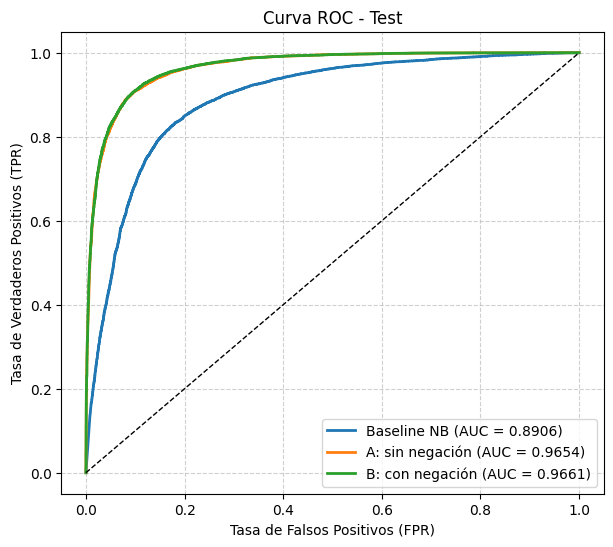

In [23]:
plt.figure(figsize=(7, 6))
for nombre, modelo, X in [("Baseline NB", nb, X_test),
                          ("A: sin negación", lr_A, XA_test),
                          ("B: con negación", lr_B, XB_test)]:
    fpr, tpr, _ = roc_curve(y_test, modelo.predict_proba(X)[:, 1])
    plt.plot(fpr, tpr, lw=2, label=f"{nombre} (AUC = {auc(fpr, tpr):.4f})")
plt.plot([0, 1], [0, 1], "k--", lw=1)
plt.xlabel("Tasa de Falsos Positivos (FPR)"); plt.ylabel("Tasa de Verdaderos Positivos (TPR)")
plt.title("Curva ROC - Test"); plt.legend(loc="lower right"); plt.grid(True, linestyle="--", alpha=0.6)
plt.show()

### Curva ROC

Se compara la tasa de verdaderos positivos con la tasa de falsos positivos para distintos umbrales. El AUC resume la capacidad de discriminación de cada modelo.

El Modelo B presenta el AUC más alto, aunque la diferencia respecto al Modelo A es pequeña.

###Etapa 3- **Mejora**. Promedio de vectores Word2vec preentrenados + MLP; comparación con la Etapa 2

**Idea:** en lugar de contar palabras (BoW / TF-IDF), representamos cada palabra con un vector denso de 300 dimensiones
(Word2vec de Google News) y cada reseña como el **promedio** de los vectores de sus palabras.
Sobre esa representación entrenamos un MLP.

In [24]:
!pip install gensim

import numpy as np
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.preprocessing import StandardScaler
import gensim.downloader as api

# Semillas para reproducibilidad
SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)

# Word2vec de Google News (3 millones de palabras, 300 dimensiones).
# La primera vez descarga ~1.6 GB, puede tardar unos minutos.
w2v = api.load("word2vec-google-news-300")
print("Vocabulario:", len(w2v.key_to_index), "| Dimensión:", w2v.vector_size)

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 27.8/27.8 MB 44.7 MB/s  0:00:00
[==================================================] 100.0% 1662.8/1662.8MB downloaded
Vocabulario: 3000000 | Dimensión: 300


3.1 Representación de las reseñas: promedio de vectores Word2vec

Se usa el texto limpio de la Etapa 1 (`clean`), ya que Word2vec no contiene tokens como `NEG_good`. Las palabras que no existen en Word2vec se ignoran. Se usan las mismas particiones Train / Dev / Test de las etapas anteriores y se estandarizan los vectores (ajustando el escalador **solo** con Train).

In [25]:
def vector_promedio(texto):
    """Promedia los vectores Word2vec de las palabras de una reseña.
    Ignora palabras fuera del vocabulario; si no hay ninguna, regresa ceros."""
    vectores = [w2v[t] for t in texto.split() if t in w2v.key_to_index]
    if len(vectores) == 0:
        return np.zeros(w2v.vector_size, dtype=np.float32)
    return np.mean(vectores, axis=0)

# Matrices de entrada
Xw_train = np.vstack([vector_promedio(t) for t in train["clean"]])
Xw_dev   = np.vstack([vector_promedio(t) for t in dev["clean"]])
Xw_test  = np.vstack([vector_promedio(t) for t in test["clean"]])

# Estandarización: fit SOLO con train
scaler = StandardScaler()
Xw_train = scaler.fit_transform(Xw_train)
Xw_dev   = scaler.transform(Xw_dev)
Xw_test  = scaler.transform(Xw_test)

print("Train:", Xw_train.shape, "| Dev:", Xw_dev.shape, "| Test:", Xw_test.shape)

Train: (20000, 300) | Dev: (5000, 300) | Test: (25000, 300)


3.2 Modelo C: Word2vec promedio + MLP

Se entrena un MLP con dos capas ocultas (ReLU + Dropout) y una salida sigmoide. Se usa Dev para monitorear el entrenamiento y detenerlo cuando deja de mejorar; Test no se utiliza aquí.

In [26]:
# Arquitectura del MLP
mlp = keras.Sequential([
    layers.Input(shape=(300,)),
    layers.Dense(256, activation="relu"),
    layers.Dropout(0.3),                     # regularización
    layers.Dense(64, activation="relu"),
    layers.Dropout(0.3),
    layers.Dense(1, activation="sigmoid")    # probabilidad de reseña positiva
])

mlp.compile(optimizer=keras.optimizers.Adam(learning_rate=1e-3),
            loss="binary_crossentropy",
            metrics=["accuracy"])

# Se detiene si la pérdida en Dev no mejora en 5 épocas y se conservan los mejores pesos
early_stop = keras.callbacks.EarlyStopping(monitor="val_loss", patience=5,
                                           restore_best_weights=True)

historial = mlp.fit(Xw_train, y_train.values,
                    validation_data=(Xw_dev, y_dev.values),
                    epochs=50, batch_size=128,
                    callbacks=[early_stop], verbose=2)

Epoch 1/50
157/157 - 4s - 25ms/step - accuracy: 0.8044 - loss: 0.4304 - val_accuracy: 0.8548 - val_loss: 0.3438
Epoch 2/50
157/157 - 2s - 11ms/step - accuracy: 0.8531 - loss: 0.3470 - val_accuracy: 0.8600 - val_loss: 0.3283
Epoch 3/50
157/157 - 2s - 12ms/step - accuracy: 0.8613 - loss: 0.3257 - val_accuracy: 0.8658 - val_loss: 0.3239
Epoch 4/50
157/157 - 2s - 12ms/step - accuracy: 0.8736 - loss: 0.3063 - val_accuracy: 0.8658 - val_loss: 0.3213
Epoch 5/50
157/157 - 2s - 12ms/step - accuracy: 0.8780 - loss: 0.2938 - val_accuracy: 0.8662 - val_loss: 0.3198
Epoch 6/50
157/157 - 2s - 12ms/step - accuracy: 0.8812 - loss: 0.2831 - val_accuracy: 0.8710 - val_loss: 0.3185
Epoch 7/50
157/157 - 2s - 11ms/step - accuracy: 0.8880 - loss: 0.2710 - val_accuracy: 0.8688 - val_loss: 0.3198
Epoch 8/50
157/157 - 3s - 16ms/step - accuracy: 0.8915 - loss: 0.2593 - val_accuracy: 0.8664 - val_loss: 0.3220
Epoch 9/50
157/157 - 2s - 11ms/step - accuracy: 0.8955 - loss: 0.2510 - val_accuracy: 0.8664 - val_loss:

3.3 Evaluación del Modelo C en Dev

In [27]:
def metricas_keras(modelo, X, y):
    """Mismas métricas que `metricas()` de la Etapa 2, pero para un modelo de Keras."""
    proba = modelo.predict(X, verbose=0).ravel()
    pred  = (proba >= 0.5).astype(int)
    return {"Exactitud": accuracy_score(y, pred),
            "F1": f1_score(y, pred),
            "AUC-ROC": roc_auc_score(y, proba)}

pred_dev_C = (mlp.predict(Xw_dev, verbose=0).ravel() >= 0.5).astype(int)
print({k: round(v, 4) for k, v in metricas_keras(mlp, Xw_dev, y_dev).items()})
print(classification_report(y_dev, pred_dev_C, target_names=["neg", "pos"]))

{'Exactitud': 0.871, 'F1': 0.8709, 'AUC-ROC': np.float64(0.9391)}
              precision    recall  f1-score   support

         neg       0.87      0.87      0.87      2500
         pos       0.87      0.87      0.87      2500

    accuracy                           0.87      5000
   macro avg       0.87      0.87      0.87      5000
weighted avg       0.87      0.87      0.87      5000



3.4 Comparación con la Etapa 2: Baseline vs Modelo A vs Modelo B vs Modelo C


In [28]:
# Agregamos el Modelo C
resultados["C: Word2vec promedio + MLP"] = (metricas_keras(mlp, Xw_dev,  y_dev),
                                            metricas_keras(mlp, Xw_test, y_test))

filas = []
for nombre, (m_dev, m_test) in resultados.items():
    fila = {"Modelo": nombre}
    fila.update({f"Dev {k}": v for k, v in m_dev.items()})
    fila.update({f"Test {k}": v for k, v in m_test.items()})
    filas.append(fila)

tabla_final = pd.DataFrame(filas).set_index("Modelo").round(4)
display(tabla_final)

# Diferencia de C respecto al mejor modelo de la Etapa 2 (B) en Test
print("\nDiferencia C - B en Test:")
for k in ["Exactitud", "F1", "AUC-ROC"]:
    d = resultados["C: Word2vec promedio + MLP"][1][k] - resultados["B: TF-IDF 1-2g + LR (con negación)"][1][k]
    print(f"  {k:<10}: {d:+.4f}")

,Dev Exactitud,Dev F1,Dev AUC-ROC,Test Exactitud,Test F1,Test AUC-ROC
Modelo,,,,,,
Baseline: BoW + Naive Bayes,0.8410,0.8334,0.9180,0.8130,0.8002,0.8906
A: TF-IDF 1-2g + LR (sin negación),0.9092,0.9096,0.9701,0.9048,0.9048,0.9654
B: TF-IDF 1-2g + LR (con negación),0.9110,0.9114,0.9700,0.9049,0.9050,0.9661
C: Word2vec promedio + MLP,0.8710,0.8709,0.9391,0.8570,0.8568,0.9335



Diferencia C - B en Test:
  Exactitud : -0.0480
  F1        : -0.0481
  AUC-ROC   : -0.0326


### Curva ROC comparativa


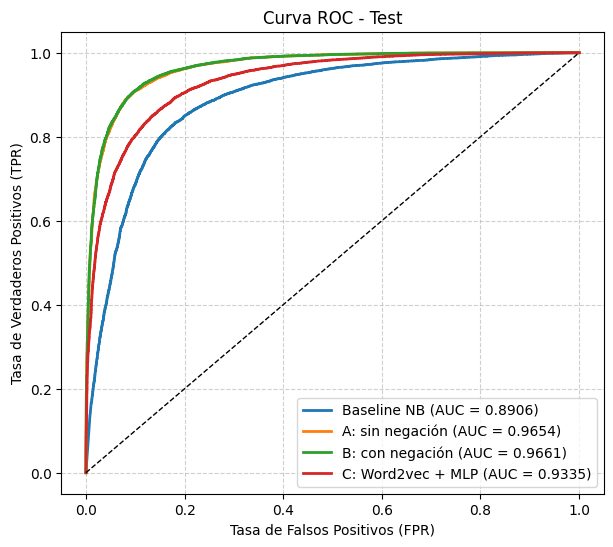

In [29]:
plt.figure(figsize=(7, 6))
for nombre, proba in [
    ("Baseline NB",       nb.predict_proba(X_test)[:, 1]),
    ("A: sin negación",   lr_A.predict_proba(XA_test)[:, 1]),
    ("B: con negación",   lr_B.predict_proba(XB_test)[:, 1]),
    ("C: Word2vec + MLP", mlp.predict(Xw_test, verbose=0).ravel()),
]:
    fpr, tpr, _ = roc_curve(y_test, proba)
    plt.plot(fpr, tpr, lw=2, label=f"{nombre} (AUC = {auc(fpr, tpr):.4f})")
plt.plot([0, 1], [0, 1], "k--", lw=1)
plt.xlabel("Tasa de Falsos Positivos (FPR)"); plt.ylabel("Tasa de Verdaderos Positivos (TPR)")
plt.title("Curva ROC - Test"); plt.legend(loc="lower right"); plt.grid(True, linestyle="--", alpha=0.6)
plt.show()